# Задача 7: Методи регресійного аналізу в Python

Загальна мета полягає в тому, щоб пояснити ціни продажу SalePrice за допомогою набору змінних, використовуючи набір даних із попереднього домашнього завдання (Ames Housing). Змінна SalePrice приймається як залежна змінна (target), а решта змінних – як пояснювальні (features).

***Answer***

[Умова](../input/assignment_4.pdf). Використовуємо повний Ames Housing із task3; `SalePrice` вимірюється в доларах США, площі в квадратних футах. Структурне `NA` (наприклад, відсутність каміна) зберігаємо як категорію; порожнє поле вважаємо пропуском.

Вилучаємо ідентифікатори `Order`, `PID` та `GarageYrBlt`: для будинків без гаража рік його побудови не визначений. Решту ознак залишаємо, зокрема корельовані площі. `MSSubClass` є категорією, а `OverallQual` та `OverallCond` залишаємо числовими порядковими оцінками.

До навчання відкладаємо 20% рядків для кінцевої перевірки (`random_state=42`). Числові пропуски заповнюємо медіаною навчальної частини, категоріальні окремим рівнем `Missing`. Числові ознаки стандартизуємо, даммі залишаємо у шкалі 0/1. Значення штрафу вибираємо лише на навчальних даних за 5-блочною крос-валідацією з перемішуванням. Перевірочні 20% не використовуємо для вибору параметрів.

Порівняння дисперсій у (г) умовне: фіксуємо матрицю ознак і вибраний штраф та припускаємо лінійну модель з незалежними похибками однакової дисперсії. Це не перевірка істинності таких припущень для цін будинків.

In [1]:
# Імпорти та спільні налаштування.
# ========= YOUR CODE STARTS HERE ========= #
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LassoCV, Ridge, LinearRegression, lasso_path
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TASK_DIR = Path.cwd()
if (TASK_DIR / "labs" / "task4").is_dir():
    TASK_DIR = TASK_DIR / "labs" / "task4"
elif TASK_DIR.name == "notebooks":
    TASK_DIR = TASK_DIR.parent
DATA_PATH = TASK_DIR.parent / "task3" / "input" / "AmesHousing.txt"
FIGURES_DIR = TASK_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
SEED = 42
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
pd.set_option("display.max_rows", 350)
pd.set_option("display.float_format", "{:.6g}".format)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

# Невідомі категорії обліковуємо явно; прибираємо лише повтори цього попередження.
warnings.filterwarnings(
    "ignore", message="Found unknown categories in columns.*",
    category=UserWarning, module="sklearn.preprocessing._encoders",
)

In [2]:
# Завантаження та підготовка даних.
# ========= YOUR CODE STARTS HERE ========= #
df = pd.read_csv(DATA_PATH, sep="\t", keep_default_na=False, na_values=[""])
df.columns = df.columns.str.replace(" ", "").str.replace("/", "")
for column in df.select_dtypes(exclude="number").columns:
    df[column] = df[column].str.strip()
df["MSSubClass"] = df["MSSubClass"].astype(str)
X = df.drop(columns=["SalePrice", "Order", "PID", "GarageYrBlt"])
y = df["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()
display(pd.Series({
    "Спостережень": len(df), "Навчальна частина": len(X_train),
    "Перевірочна частина": len(X_test), "Числових ознак": len(numeric_columns),
    "Категоріальних ознак": len(categorical_columns),
    "Пропусків у SalePrice": y.isna().sum(),
}).to_frame("Значення"))
display(df["FireplaceQu"].value_counts(dropna=False).rename_axis("FireplaceQu").to_frame("Кількість"))

,Значення
Спостережень,2930
Навчальна частина,2344
Перевірочна частина,586
Числових ознак,34
Категоріальних ознак,44
Пропусків у SalePrice,0


,Кількість
FireplaceQu,
NA,1422
Gd,744
TA,600
Fa,75
Po,46
Ex,43


## (1)

Регресія ласо (Lasso) та рідж-регресія (Ridge) є методами регуляризації, які використовуються для стабілізації оцінювання параметрів.

### (а)

Поясніть своїми словами концепцію регресії ласо. Опишіть сценарій, за якого звичайна лінійна регресія зазнає невдачі (наприклад, через мультиколінеарність або коли $p > n$), але регресію ласо все ще можна оцінити. Чому нам потрібно максимізувати цільову функцію чисельно (на відміну від рідж-регресії, яка має аналітичний розв'язок)?

In [3]:
# ========= YOUR CODE STARTS HERE ========= #
# Теоретична відповідь наведена нижче; обчислення не потрібні.

***Answer***

Lasso додає до суми квадратів залишків штраф за суму модулів коефіцієнтів. Штраф зменшує коефіцієнти, а частину може зробити точно нульовими, тому Lasso одночасно виконує відбір ознак.
$$RSS+\lambda\sum_{j=1}^{p}|\beta_j|\longrightarrow\min.$$
Тут $RSS$ позначає суму квадратів залишків, $\lambda>0$ є силою штрафу, $p$ кількістю ознак, а $\beta_j$ коефіцієнтом ознаки з номером $j$. Вільний член у цьому записі опущено завдяки центруванню даних.

Якщо дві ознаки дублюють одна одну або ознак більше, ніж спостережень ($p>n$, де $n$ позначає кількість спостережень), матриця $X^TX$ вироджена і звичайна формула МНК з оберненою матрицею не працює. Тут $X$ позначає матрицю ознак. Мінімум RSS усе ще існує, але коефіцієнти можуть бути неєдиними. Сильна, але неточна колінеарність робить оцінки нестійкими. Lasso зі штрафом можна оцінити й у цих випадках, хоча при точному дублюванні ознак його коефіцієнти теж не обов'язково єдині.

Функцію потрібно мінімізувати, а не максимізувати. Модуль не має похідної в нулі, тому для загальної матриці ознак немає простої матричної формули, як у Ridge. Один із чисельних методів, покоординатний спуск, по черзі оновлює коефіцієнти до збіжності. Для спеціальних випадків, наприклад ортогональних ознак, явний розв'язок існує.

### (б)

Для звичайної регресії МНК змінні рідко нормуються. Однак у випадку ласо-регресії масштабування є критичним, оскільки штраф накладається безпосередньо на абсолютну величину коефіцієнтів. Чому це так? Масштабуйте числові дані за допомогою StandardScaler. Чи можна / чи потрібно масштабувати бінарні змінні (даммі) в такий самий спосіб? Як обробити факторні змінні (наприклад, FireplaceQu) через OneHotEncoder?

In [4]:
# ========= YOUR CODE STARTS HERE ========= #
# Кожне перетворення навчається лише на переданій навчальній частині.
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_columns),
    ("cat", categorical_pipe, categorical_columns),
], verbose_feature_names_out=False)
prepared = clone(preprocessor).fit(X_train)
Z_train = prepared.transform(X_train)
Z_test = prepared.transform(X_test)
feature_names = prepared.get_feature_names_out()
scaler = prepared.named_transformers_["num"].named_steps["scale"]
display(pd.DataFrame({
    "Ознака": numeric_columns,
    "Середнє після заповнення": scaler.mean_,
    "Масштаб StandardScaler": scaler.scale_,
    "Середнє після стандартизації": Z_train[:, :len(numeric_columns)].mean(axis=0),
    "SD після стандартизації": Z_train[:, :len(numeric_columns)].std(axis=0),
}))
encoder = prepared.named_transformers_["cat"].named_steps["encode"]
fireplace_index = categorical_columns.index("FireplaceQu")
print("Рівні FireplaceQu:", encoder.categories_[fireplace_index])
print("Базовий рівень:", encoder.categories_[fireplace_index][encoder.drop_idx_[fireplace_index]])
print("Даммі FireplaceQu:", [name for name in feature_names if name.startswith("FireplaceQu_")])
print("Розмір матриці після кодування:", Z_train.shape)
assert np.isfinite(Z_train).all() and np.isfinite(Z_test).all()
assert set(np.unique(Z_train[:, len(numeric_columns):])).issubset({0.0, 1.0})

# Показуємо кількість значень, категорії яких відсутні в навчальній частині.
unknown_counts = {}
for column, categories in zip(categorical_columns, encoder.categories_):
    values = X_test[column].fillna("Missing")
    count = (~values.isin(categories)).sum()
    if count:
        unknown_counts[column] = count
display(pd.Series(unknown_counts, name="Невідомих значень у перевірочній частині").rename_axis("Ознака").to_frame())

,Ознака,Середнє після заповнення,Масштаб StandardScaler,Середнє після стандартизації,SD після стандартизації
0,LotFrontage,69.0051,21.3641,-1.9076e-16,1
1,LotArea,10127.9,8049.19,6.37289e-17,1
2,OverallQual,6.06442,1.38822,-7.48359e-17,1
3,OverallCond,5.58191,1.10542,-2.17687e-16,1
4,YearBuilt,1970.51,30.335,-2.71327e-15,1
5,YearRemodAdd,1983.92,20.7819,-3.50435e-15,1
6,MasVnrArea,97.741,171.73,1.28074e-16,1
7,BsmtFinSF1,442.503,452.032,-9.52026e-18,1
8,BsmtFinSF2,50.0759,170.327,5.66905e-16,1
9,BsmtUnfSF,554.354,433.607,-4.9259e-18,1


Рівні FireplaceQu: ['Ex' 'Fa' 'Gd' 'NA' 'Po' 'TA']
Базовий рівень: Ex
Даммі FireplaceQu: ['FireplaceQu_Fa', 'FireplaceQu_Gd', 'FireplaceQu_NA', 'FireplaceQu_Po', 'FireplaceQu_TA']
Розмір матриці після кодування: (2344, 294)


,Невідомих значень у перевірочній частині
Ознака,
Exterior2nd,1
Electrical,1
KitchenQual,1
MiscFeature,1


***Answer***

Якщо площу перевести у більші одиниці, її коефіцієнт має збільшитися, щоб прогноз залишився тим самим. RSS від цього не зміниться, а штраф за модуль коефіцієнта зросте. Тому без масштабування Lasso нерівномірно штрафує однакові за змістом ефекти.

`StandardScaler` обчислює $z_{ij}=(x_{ij}-\bar x_j)/s_j$, де $x_{ij}$ є значенням ознаки $j$ для будинку $i$, $\bar x_j$ її навчальним середнім, а $s_j$ навчальним стандартним відхиленням із дільником $n$; $z_{ij}$ є стандартизованим значенням. Після цього числовий коефіцієнт описує зміну ціни при збільшенні ознаки на одне навчальне стандартне відхилення. Для звичайного МНК з вільним членом таке оборотне перетворення не змінює підгонку, хоча може покращити числову стійкість.

Даммі теж можна стандартизувати: для частки одиниць $q$ її стандартне відхилення дорівнює $\sqrt{q(1-q)}$. Це змінює відносну силу штрафу для рідкісних і частих категорій. Єдиного обов'язкового вибору немає. Тут залишаємо даммі у шкалі 0/1, щоб коефіцієнт відповідав переходу від базової категорії до заданої; це свідомий вибір шкали штрафу.

`OneHotEncoder(drop="first")` створює індикатори для всіх категорій, крім базової. Для `FireplaceQu` базовий рівень `Ex`, а `NA` означає відсутність каміна й має окрему даммі.

Параметри масштабування та перелік категорій визначаємо за навчальними даними.


### (в)

Запустіть регресію ласо за допомогою Lasso або LassoCV з коефіцієнтом регуляризації $\alpha > 0$ ($\alpha$ в sklearn відповідає $\lambda$ в теоретичних формулах). Побудуйте графік залежності оцінених параметрів від $\alpha$. Яке значення $\alpha$ ви б рекомендували? Визначте оптимальний $\alpha$ за допомогою 5-блочної крос-валідації (LassoCV).

,Метод,alpha,"CV MSE, дол.^2"
0,LassoCV: спільна підготовка,76.2699,9.81199e+08
1,Pipeline: підготовка в кожному блоці,76.2699,9.82068e+08


Ненульових коефіцієнтів: 126 із 294
Ітерацій фінальної моделі: 579
Відносний dual gap: 9.830565287744918e-07


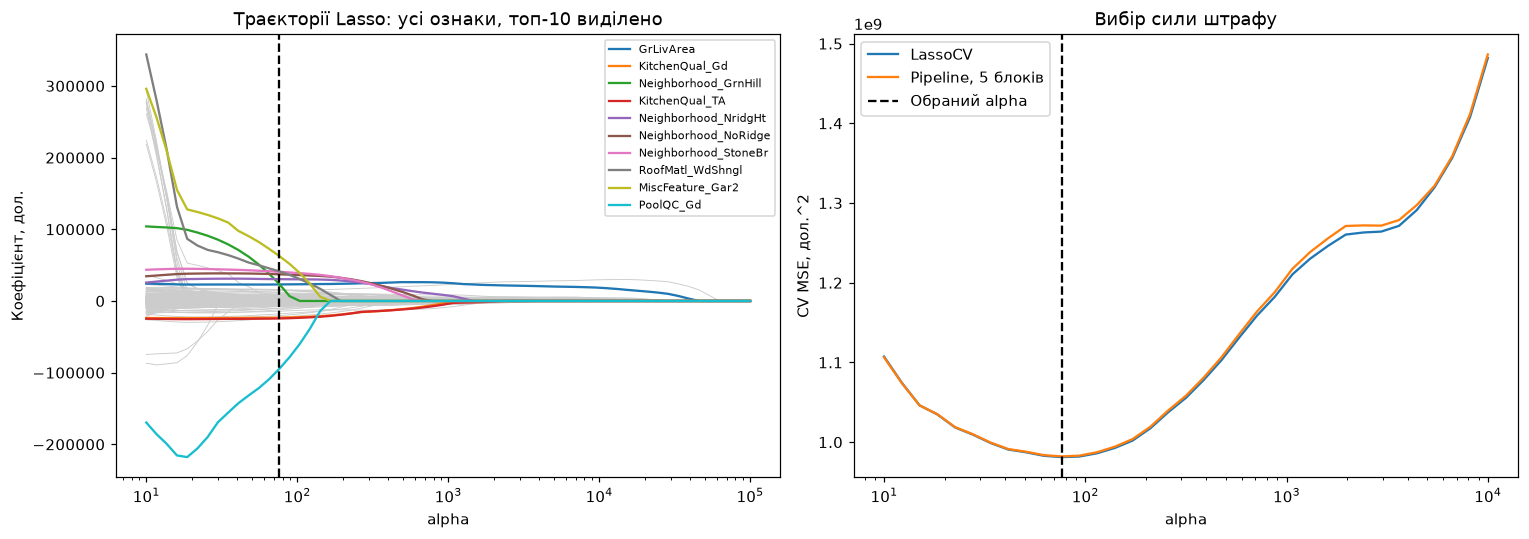

,Коефіцієнт Lasso
PoolQC_Gd,-94452.8
MiscFeature_Gar2,62519.3
RoofMatl_WdShngl,41280.6
Neighborhood_StoneBr,40662.6
Neighborhood_NoRidge,37231.7
Neighborhood_NridgHt,30428.6
KitchenQual_TA,-24421.7
Neighborhood_GrnHill,23490.9
KitchenQual_Gd,-23299.2
GrLivArea,23057.6


In [5]:
# ========= YOUR CODE STARTS HERE ========= #
lasso_alphas = np.logspace(1, 4, 35)
# LassoCV виконує п'ять блоків на вже підготовленій матриці.
lasso_cv = LassoCV(alphas=lasso_alphas, cv=cv, max_iter=50000, tol=1e-6)
lasso_cv.fit(Z_train, y_train)

# Перевіряємо вибір штрафу без спільного масштабування між блоками.
lasso_search = GridSearchCV(
    Pipeline([("prepare", clone(preprocessor)),
              ("model", Lasso(max_iter=50000, tol=1e-6))]),
    {"model__alpha": lasso_alphas}, cv=cv,
    scoring="neg_mean_squared_error", n_jobs=1,
)
lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_.named_steps["model"]
lasso_alpha = lasso_search.best_params_["model__alpha"]
lasso_results = pd.DataFrame({
    "Метод": ["LassoCV: спільна підготовка", "Pipeline: підготовка в кожному блоці"],
    "alpha": [lasso_cv.alpha_, lasso_alpha],
    "CV MSE, дол.^2": [lasso_cv.mse_path_.mean(axis=1).min(), -lasso_search.best_score_],
})
display(lasso_results)
print("Ненульових коефіцієнтів:", np.count_nonzero(lasso_model.coef_), "із", len(feature_names))
print("Ітерацій фінальної моделі:", lasso_model.n_iter_)
print("Відносний dual gap:", lasso_model.dual_gap_ / np.var(y_train))

# Центрування потрібне, бо lasso_path не оцінює вільний член.
path_alphas, coefficients, gaps = lasso_path(
    Z_train - Z_train.mean(axis=0), y_train.to_numpy() - y_train.mean(),
    alphas=np.logspace(1, 5, 60), max_iter=50000, tol=1e-6,
)
top = np.argsort(np.abs(lasso_model.coef_))[-10:]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(path_alphas, coefficients.T, color="0.8", linewidth=0.6)
for index in top:
    axes[0].plot(path_alphas, coefficients[index], label=feature_names[index])
axes[0].axvline(lasso_alpha, color="black", linestyle="--")
axes[0].set(xscale="log", xlabel="alpha", ylabel="Коефіцієнт, дол.", title="Траєкторії Lasso: усі ознаки, топ-10 виділено")
axes[0].legend(fontsize=7, loc="best")
axes[1].plot(lasso_cv.alphas_, lasso_cv.mse_path_.mean(axis=1), label="LassoCV")
axes[1].plot(lasso_alphas, -lasso_search.cv_results_["mean_test_score"], label="Pipeline, 5 блоків")
axes[1].axvline(lasso_alpha, color="black", linestyle="--", label="Обраний alpha")
axes[1].set(xscale="log", xlabel="alpha", ylabel="CV MSE, дол.^2", title="Вибір сили штрафу")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part1_lasso.png")
plt.show()
lasso_coefficients = pd.Series(lasso_model.coef_, index=feature_names, name="Коефіцієнт Lasso")
display(lasso_coefficients[lasso_coefficients != 0].sort_values(key=abs, ascending=False).to_frame())
assert lasso_alphas.min() < lasso_alpha < lasso_alphas.max()
assert lasso_model.n_iter_ < lasso_model.max_iter
assert lasso_model.dual_gap_ / np.var(y_train) < 1e-6

***Answer***

Середня квадратична помилка прогнозу визначається як $MSE=\frac{1}{m}\sum_{i=1}^{m}(y_i-\widehat y_i)^2$, де $m$ є кількістю перевірочних спостережень, $y_i$ фактичною ціною, а $\widehat y_i$ прогнозом для будинку $i$. Одиниці MSE тут дол.². Для крос-валідації обчислюємо цю помилку окремо на кожному відкладеному блоці.

Для кожного штрафу навчаємо модель на чотирьох блоках і прогнозуємо п'ятий. Вибираємо мінімум $CV(\alpha)=\frac15\sum_{k=1}^{5}MSE_k(\alpha)$, де $MSE_k$ є середньою квадратичною помилкою на відкладеному блоці $k$. Це найкраще значення серед перевіреної сітки, а не доведений мінімум серед усіх додатних чисел.

`LassoCV` виконує вимогу завдання, але отримує вже масштабовану матрицю: середні та медіани тоді використовують усю навчальну частину, включно з внутрішніми перевірочними блоками. Тому додатково застосовано `GridSearchCV` до повного `Pipeline`, де підготовка відбувається окремо в кожному блоці. Для фінальної моделі рекомендую штраф із цього другого порівняння; конкретні значення, CV MSE та кількість ненульових коефіцієнтів наведено вище.

На графіку зростання штрафу приводить коефіцієнти до нуля; окремі траєкторії можуть бути немонотонними через зв'язки між ознаками. Вільний член зберігається. Нульовий коефіцієнт означає, що ознака не використовується цією моделлю за обраного штрафу; це не доказ відсутності її економічного впливу.

В обох способах вибору отримано $\alpha \approx 76.27$. Це внутрішня точка сітки, а не її межа. У sklearn цільова функція ділить RSS на $2n$, тому $\alpha$ бібліотеки відповідає $\lambda/(2n)$ у записі формули з пункту (а): для порівняння з нею $\lambda=2n\alpha$. Lasso лишає ненульовими 126 коефіцієнтів із 294. За дуже великих штрафів модель втрачає корисні ознаки, що видно зі зростання CV MSE.

### (г)

Розгляньте рідж-регресію (Ridge або RidgeCV). Оцініть її для оптимального значення $\alpha$, знайденого через крос-валідацію. Порівняйте оцінені параметри та їхні дисперсії для рідж-регресії та множинної лінійної регресії (LinearRegression). Чого ви очікуєте від такого порівняння з точки зору компромісу між зміщенням та дисперсією (bias-variance tradeoff)? Не забудьте підігнати лінійну регресію до попередньо масштабованих змінних.

Прогноз: менші умовні дисперсії Ridge; перевага за перевірочною MSE не гарантована.


,alpha,"Навчальна MSE, дол.^2","Перевірочна MSE, дол.^2",Норма коефіцієнтів
Модель,,,,
OLS,0,3.50384e+08,1.24388e+09,2.21385e+06
Lasso,76.2699,5.5878e+08,8.54966e+08,158985
Ridge,2.15443,4.95726e+08,8.43583e+08,206753


Ridge: мінімальна CV MSE, дол.^2: 976187864.1906097
Ранг центрованої матриці / кількість ознак: 280 / 294
Оцінка дисперсії похибки, дол.^2: 398109338.6626817
Сума дисперсій OLS та Ridge: 61977050639.282486 4795464375.7660475


,OLS,Ridge,"Var OLS, дол.^2","Var Ridge, дол.^2",Var Ridge / Var OLS
Ознака,,,,,
LotFrontage,1350.95,-1642.45,439737,380368,0.86499
LotArea,5462.63,4115.2,422033,343163,0.81312
OverallQual,8711.49,11650.9,912309,804783,0.882139
OverallCond,6698.35,5865.8,420234,378228,0.900042
YearBuilt,12549.5,8961.85,2.96605e+06,2.40766e+06,0.811738
YearRemodAdd,1021.81,1292.28,581260,541923,0.932324
MasVnrArea,3286.45,2327.17,553265,495694,0.895942
BsmtFinSF1,9812.54,3912.92,2.90127e+06,501621,0.172897
BsmtFinSF2,2459.41,2057.8,967681,570356,0.589405


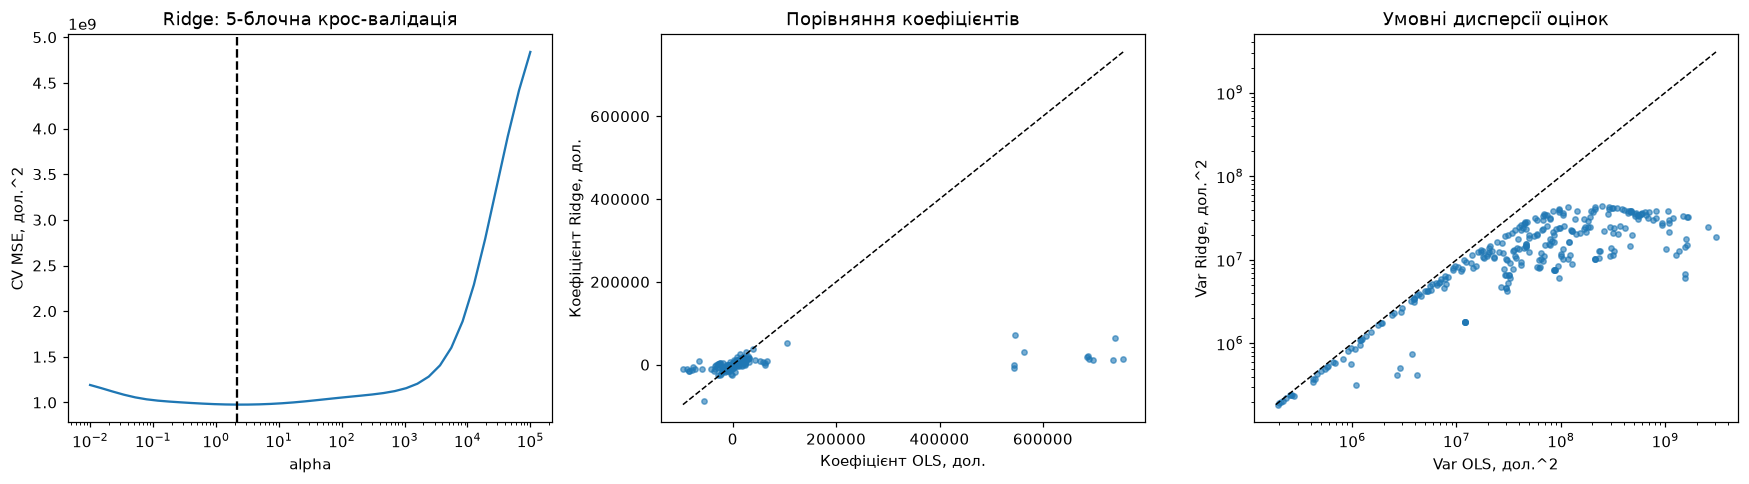

In [6]:
# ========= YOUR CODE STARTS HERE ========= #
# Прогноз перед обчисленням: Ridge зменшить умовні дисперсії коефіцієнтів,
# але його помилка на нових даних не обов'язково буде меншою за МНК.
print("Прогноз: менші умовні дисперсії Ridge; перевага за перевірочною MSE не гарантована.")
ridge_alphas = np.logspace(-2, 5, 40)
ridge_search = GridSearchCV(
    Pipeline([("prepare", clone(preprocessor)), ("model", Ridge(solver="svd"))]),
    {"model__alpha": ridge_alphas}, cv=cv,
    scoring="neg_mean_squared_error", n_jobs=1,
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_.named_steps["model"]
ridge_alpha = ridge_search.best_params_["model__alpha"]
ols_model = LinearRegression().fit(Z_train, y_train)

# Усі три моделі використовують ту саму матрицю й ті самі рядки.
metrics = []
for name, model in [("OLS", ols_model), ("Lasso", lasso_model), ("Ridge", ridge_model)]:
    metrics.append({
        "Модель": name,
        "alpha": {"OLS": 0, "Lasso": lasso_alpha, "Ridge": ridge_alpha}[name],
        "Навчальна MSE, дол.^2": mean_squared_error(y_train, model.predict(Z_train)),
        "Перевірочна MSE, дол.^2": mean_squared_error(y_test, model.predict(Z_test)),
        "Норма коефіцієнтів": np.linalg.norm(model.coef_),
    })
display(pd.DataFrame(metrics).set_index("Модель"))
print("Ridge: мінімальна CV MSE, дол.^2:", -ridge_search.best_score_)

# За точної колінеарності МНК повертає розв'язок найменшої норми.
# Псевдообернена матриця дозволяє порівняти саме цей розв'язок із Ridge.
Z_centered = Z_train - Z_train.mean(axis=0)
rank = ols_model.rank_
sigma2 = np.sum((y_train - ols_model.predict(Z_train)) ** 2) / (len(y_train) - rank - 1)
Z_pinv = np.linalg.pinv(Z_centered, rcond=max(Z_centered.shape) * np.finfo(float).eps)
A_ridge = np.linalg.solve(
    Z_centered.T @ Z_centered + ridge_alpha * np.eye(Z_train.shape[1]),
    Z_centered.T,
)
var_ols = sigma2 * np.sum(Z_pinv ** 2, axis=1)
var_ridge = sigma2 * np.sum(A_ridge ** 2, axis=1)
comparison = pd.DataFrame({
    "OLS": ols_model.coef_, "Ridge": ridge_model.coef_,
    "Var OLS, дол.^2": var_ols, "Var Ridge, дол.^2": var_ridge,
    "Var Ridge / Var OLS": np.divide(var_ridge, var_ols, out=np.full_like(var_ols, np.nan), where=var_ols > 0),
}, index=pd.Index(feature_names, name="Ознака"))
print("Ранг центрованої матриці / кількість ознак:", rank, "/", Z_train.shape[1])
print("Оцінка дисперсії похибки, дол.^2:", sigma2)
print("Сума дисперсій OLS та Ridge:", var_ols.sum(), var_ridge.sum())
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(ridge_alphas, -ridge_search.cv_results_["mean_test_score"])
axes[0].axvline(ridge_alpha, color="black", linestyle="--")
axes[0].set(xscale="log", xlabel="alpha", ylabel="CV MSE, дол.^2", title="Ridge: 5-блочна крос-валідація")
axes[1].scatter(ols_model.coef_, ridge_model.coef_, s=12, alpha=0.6)
limits = [min(ols_model.coef_.min(), ridge_model.coef_.min()), max(ols_model.coef_.max(), ridge_model.coef_.max())]
axes[1].plot(limits, limits, "k--", linewidth=1)
axes[1].set(xlabel="Коефіцієнт OLS, дол.", ylabel="Коефіцієнт Ridge, дол.", title="Порівняння коефіцієнтів")
positive = (var_ols > 0) & (var_ridge > 0)
axes[2].scatter(var_ols[positive], var_ridge[positive], s=12, alpha=0.6)
limits = [min(var_ols[positive].min(), var_ridge[positive].min()), max(var_ols.max(), var_ridge.max())]
axes[2].plot(limits, limits, "k--", linewidth=1)
axes[2].set(xscale="log", yscale="log", xlabel="Var OLS, дол.^2", ylabel="Var Ridge, дол.^2", title="Умовні дисперсії оцінок")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part1_ridge_ols.png")
plt.show()

# Перевіряємо формули та однакове перетворення даних у фінальних моделях.
assert np.allclose(Z_pinv @ (y_train - y_train.mean()), ols_model.coef_)
assert np.allclose(A_ridge @ (y_train - y_train.mean()), ridge_model.coef_)
assert np.all(var_ridge <= var_ols + 1e-6 * var_ols.max())
assert ridge_alphas.min() < ridge_alpha < ridge_alphas.max()
for search in [lasso_search, ridge_search]:
    assert np.allclose(search.best_estimator_.named_steps["prepare"].transform(X_train), Z_train)
    assert np.allclose(search.predict(X_test), search.best_estimator_.named_steps["model"].predict(Z_test))

***Answer***

**Очікування до обчислень:** додатний штраф Ridge зменшить умовні дисперсії оцінок, але внесе зміщення. Менша дисперсія не гарантує меншої помилки прогнозу на нових даних.

Обидві моделі оцінюємо на тих самих підготовлених ознаках. Ранг центрованої матриці становить 280 за 294 ознак, тому коефіцієнти МНК не єдині. Порівнюємо Ridge з розв’язком МНК, який повертає `LinearRegression`: серед розв’язків він має найменшу суму квадратів коефіцієнтів. Для нього використовуємо псевдообернену матрицю, яка працює і за залежних стовпців.

Фіксуємо матрицю ознак і вибраний штраф та припускаємо, що похибки некорельовані й мають однакову дисперсію. Оцінки матриць коваріацій коефіцієнтів мають вигляд
$$\widehat{\operatorname{Var}}(\widehat\beta_{OLS})=\widehat\sigma^2 Z^+(Z^+)^T,\qquad
\widehat{\operatorname{Var}}(\widehat\beta_R)=\widehat\sigma^2 A_RA_R^T,\qquad A_R=(Z^TZ+\alpha I)^{-1}Z^T.$$
Тут $\widehat\beta_{OLS}$ і $\widehat\beta_R$ є оцінками коефіцієнтів МНК і Ridge, $Z$ є центрованою матрицею ознак, а $Z^+$ її псевдооберненою матрицею. Матриця $A_R$ перетворює центровані ціни на оцінки Ridge, $\alpha$ є силою штрафу, $I$ одиничною матрицею, $T$ позначає транспонування, а $-1$ обернення матриці. Оцінку дисперсії похибок $\widehat\sigma^2$ отримуємо, ділячи суму квадратів залишків МНК на $n-r-1$, де $n$ є кількістю навчальних спостережень, $r$ рангом $Z$, а одиниця враховує вільний член. Діагоналі матриць дають дисперсії окремих коефіцієнтів у таблиці.

**Результати після обчислень**

Крос-валідація вибрала для Ridge $\alpha\approx2.154$. Коефіцієнт `LotArea` зменшився з 5463 до 4115 дол. на одне навчальне стандартне відхилення площі. Сума умовних дисперсій зменшилася з $6.198\cdot10^{10}$ до $4.795\cdot10^9$ дол.², як і очікували. Зміщення коефіцієнтів окремо не оцінювали.
